Every backtest so far traded at the closing price, for free. Real trading is different. Buying moves the price against you, a large order cannot be filled at once, and every second you wait the price can run away. For a large fund, the cost of trading routinely decides whether a strategy makes money at all: a signal with an edge of 20 basis points per trade is worthless if trading costs 25.

This chapter studies the two sides of that problem. The **execution** side: a fund must buy or sell a large quantity, and wants to do it cheaply without taking too much risk. The **market-making** side: a dealer stands ready to buy and sell all day, earns the bid–ask spread, and must avoid being run over by the price. Both have elegant mathematical solutions, and both are now also attacked with reinforcement learning, which we build from scratch at the end.

:::eli5
Imagine buying 500 concert tickets from a crowd of fans who each have one or two to sell. Buy them all in five minutes and word gets around: the price shoots up as you go. Buy them slowly over a week and you pay a fair price for each, but the concert might sell out or the price might rise anyway. Executing a large order is choosing between these two dangers. A **market maker** is the ticket booth: it buys from people who want to sell and sells to people who want to buy, keeping a small margin each time, and hopes it never gets stuck with a pile of tickets just as their price collapses.
:::

## Look at the big picture

- **Objective.** (1) Execute a large order (sell 10% of a day's volume of a stock) at the lowest expected cost for a chosen level of risk; (2) quote bid and ask prices as a market maker and earn the spread while keeping inventory under control.
- **Performance measures.** For execution, the **implementation shortfall** (Perold, 1988): the difference between the value of the order at the decision price and what was actually received, in basis points, with its mean *and* standard deviation. For tracking a benchmark, the tracking error against the day's VWAP. For market making, the mean and standard deviation of P&L and the size of the inventory carried.
- **Data and its limits.** Free data gives one- and five-minute bars, not the full order book or every trade. We use real bars where the question needs real markets (intraday patterns, VWAP, volatility) and well-known models and a simulator where it needs the order book. The trap at the end of the data section explains what this rules out.

## Get the data

Five-minute bars for 60 trading days (August–November 2026) for eight US stocks and ETFs, and one-minute bars for the last 20 trading days for SPY, AAPL and KO, from Yahoo Finance. Regular trading hours only (9:30–16:00 New York time).

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
import time, warnings
warnings.filterwarnings("ignore")

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

b5 = pd.read_csv(DATA / "bars_5min.csv", parse_dates=["time"])
b1 = pd.read_csv(DATA / "bars_1min.csv", parse_dates=["time"])
for b, size in [(b5, 5), (b1, 1)]:
    b["day"] = b["time"].dt.date
    b["slot"] = (b["time"].dt.hour * 60 + b["time"].dt.minute - 570) // size      # 0 = the bar starting 9:30
days = sorted(b5["day"].unique())
print(f"5-minute bars: {b5['ticker'].nunique()} tickers, {len(days)} days, {b5.groupby(['ticker', 'day']).size().median():.0f} bars a day")
print(f"1-minute bars: {sorted(b1['ticker'].unique())}, {b1['day'].nunique()} days, {b1['time'].min():%Y-%m-%d} to {b1['time'].max():%Y-%m-%d}")

5-minute bars: 8 tickers, 60 days, 78 bars a day
1-minute bars: ['AAPL', 'KO', 'SPY'], 20 days, 2026-10-07 to 2026-11-03


Daily statistics every pre-trade cost model needs: average daily volume (ADV), the typical price, and daily volatility estimated from the sum of squared five-minute returns (Chapter 3's realised variance, without the overnight gap).

In [2]:
b5["r"] = b5.groupby(["ticker", "day"])["close"].transform(lambda p: np.log(p).diff())
daily = b5.groupby(["ticker", "day"]).agg(volume=("volume", "sum"), close=("close", "last"), rv=("r", lambda r: (r**2).sum()))
stats = daily.groupby("ticker").agg(ADV=("volume", "mean"), price=("close", "mean"), daily_vol=("rv", lambda v: np.sqrt(v.mean())))
stats["ADV ($m)"] = stats["ADV"] * stats["price"] / 1e6
print(stats.assign(ADV=lambda d: (d["ADV"] / 1e6).round(1)).rename(columns={"ADV": "ADV (m shares)"}).round(4))

        ADV (m shares)     price  daily_vol    ADV ($m)
ticker                                                 
AAPL              33.2  329.7812     0.0112  10943.8739
IWM               21.5  286.4793     0.0066   6170.9497
JPM                4.6  345.5402     0.0107   1594.9271
KO                11.8   89.4878     0.0082   1051.5420
MSFT              16.6  509.9009     0.0119   8448.1907
SPY               39.6  767.4960     0.0046  30430.8735
TSLA              38.1  366.6332     0.0183  13971.1113
XOM                9.5  167.3646     0.0117   1582.6615


:::trap
Bars hide the microstructure. A one-minute bar's close is the last trade of the minute, which may have been at the bid or at the ask, so you cannot tell who initiated it, measure the spread, or see the queue of orders. Exercise 1 shows that a classic spread estimator, applied to these bars, gives absurd answers. Real execution research uses the full order-book feed (for US stocks, exchange “depth of book” data) and the trader's own fills.
:::

## How a market works: the limit order book

:::math
Most modern exchanges match orders in a **limit order book**. A *limit order* says “buy up to $q$ shares at no more than $p$” (or sell at no less); it waits in the book until it is matched or cancelled. A *market order* says “buy $q$ shares now” and is matched immediately against the best waiting orders on the other side.

- The **best bid** $b$ is the highest waiting buy price, the **best ask** $a$ the lowest waiting sell price. The **mid** is $m = (a+b)/2$ and the **spread** is $a - b$.
- The quantity waiting at each price is the **depth**. A market order larger than the depth at the best price “walks the book” and fills at progressively worse prices.
- Orders at the same price are filled in time order (price–time priority), so a limit order's place in the queue matters.

The cost of executing an order has three parts: half the spread (crossing from the mid to the ask), **price impact** (your own trading moves the price), and **timing risk** (the price moves while you are still trading). The first two argue for trading slowly and patiently, the third for trading fast. Optimal execution is the trade-off between them.
:::

## Explore the data: the intraday rhythm of markets

Trading activity is not spread evenly over the day. Volume and volatility are high at the open, when overnight news is digested, quiet at lunch, and high again into the close, when index funds and many others trade.

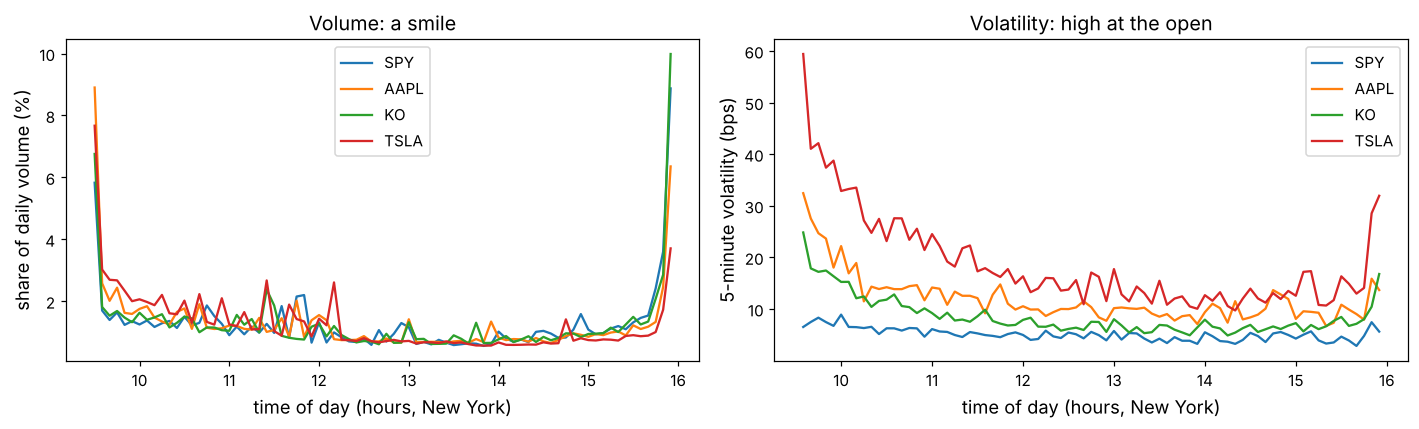

        first 30 min  last 30 min
ticker                           
AAPL           0.191        0.136
IWM            0.174        0.172
JPM            0.166        0.186
KO             0.146        0.190
MSFT           0.204        0.146
SPY            0.131        0.192
TSLA           0.204        0.091
XOM            0.144        0.223


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for tk in ["SPY", "AAPL", "KO", "TSLA"]:
    x = b5[b5["ticker"] == tk]
    share = x.groupby("day")["volume"].transform(lambda v: v / v.sum())
    prof = share.groupby(x["slot"]).mean()
    vol = x.groupby("slot")["r"].apply(lambda r: np.sqrt((r**2).mean()) * 1e4)
    ax[0].plot(prof.index * 5 / 60 + 9.5, 100 * prof, label=tk); ax[1].plot(vol.index * 5 / 60 + 9.5, vol, label=tk)
ax[0].set_ylabel("share of daily volume (%)"); ax[1].set_ylabel("5-minute volatility (bps)")
for a in ax: a.set_xlabel("time of day (hours, New York)"); a.set_xticks(range(10, 17)); a.legend()
ax[0].set_title("Volume: a smile"); ax[1].set_title("Volatility: high at the open")
save_fig("intraday"); plt.show()
first30 = b5.groupby(["ticker", "day"]).apply(lambda g: g.loc[g["slot"] < 6, "volume"].sum() / g["volume"].sum()).groupby("ticker").mean()
last30 = b5.groupby(["ticker", "day"]).apply(lambda g: g.loc[g["slot"] >= 72, "volume"].sum() / g["volume"].sum()).groupby("ticker").mean()
print(pd.DataFrame({"first 30 min": first30, "last 30 min": last30}).round(3))
R["spy_first30"] = f"{first30['SPY']:.0%}"; R["spy_last30"] = f"{last30['SPY']:.0%}"

![Figure 9-1. The intraday pattern of volume (left) and volatility (right) in five-minute bars, averaged over 60 days. Volume is U-shaped; volatility is highest at the open and decays through the day.](images/intraday.png)

For SPY, the first half hour (about 8% of the trading day) carries 13% of the volume and the last half hour 19%. This rhythm shapes every execution algorithm: an order that trades evenly through the day trades too much when the market is thin and too little when it is deep.

## Project, part 1: trading the VWAP

The most common benchmark for an execution desk is the day's **volume-weighted average price**, $\text{VWAP} = \sum_t p_t v_t / \sum_t v_t$. A client who asks for “VWAP” wants an average price close to it. Two schedules: **TWAP** trades the same amount in every five-minute slot; a **volume-profile** schedule trades in proportion to the average share of daily volume in each slot, estimated on past days.

:::math
If the schedule trades a fraction $w_t$ of the order in slot $t$ at that slot's typical price $p_t$, its average price is $\bar p = \sum_t w_t p_t$, and its tracking error against VWAP is $\bar p / \text{VWAP} - 1$. VWAP itself uses the day's *actual* volumes, which are unknown in advance, so the best a schedule can do is predict the volume shape. We estimate the profile on the first 40 days and test on the last 20, exactly like a walk-forward.
:::

In [4]:
train_days, test_days = days[:40], days[40:]
rows = []
for tk in sorted(b5["ticker"].unique()):
    x = b5[b5["ticker"] == tk].assign(typ=lambda d: (d["high"] + d["low"] + d["close"]) / 3)
    vol = x.pivot(index="day", columns="slot", values="volume"); px = x.pivot(index="day", columns="slot", values="typ")
    profile = vol.loc[train_days].div(vol.loc[train_days].sum(axis=1), axis=0).mean()
    vwap = (vol * px).sum(axis=1) / vol.sum(axis=1)
    te_prof = [(profile * px.loc[d]).sum() / vwap[d] - 1 for d in test_days]
    te_twap = [px.loc[d].mean() / vwap[d] - 1 for d in test_days]
    rows.append((tk, 1e4 * np.std(te_twap), 1e4 * np.std(te_prof)))
vwap_tab = pd.DataFrame(rows, columns=["ticker", "TWAP tracking error (bps)", "profile tracking error (bps)"]).set_index("ticker")
vwap_tab["profile better"] = vwap_tab.iloc[:, 1] < vwap_tab.iloc[:, 0]
print(vwap_tab.round(2))
R["vwap_n_better"] = int(vwap_tab["profile better"].sum()); R["vwap_n"] = len(vwap_tab)
R["tsla_twap"] = f"{vwap_tab.loc['TSLA'].iloc[0]:.0f}"; R["tsla_prof"] = f"{vwap_tab.loc['TSLA'].iloc[1]:.0f}"

        TWAP tracking error (bps)  profile tracking error (bps)  \
ticker                                                            
AAPL                        11.37                          7.67   
IWM                          6.22                          8.14   
JPM                          8.70                          7.25   
KO                           8.54                          6.32   
MSFT                        11.94                         14.42   
SPY                          5.85                          6.61   
TSLA                        26.84                          8.98   
XOM                          7.12                          4.80   

        profile better  
ticker                  
AAPL              True  
IWM              False  
JPM               True  
KO                True  
MSFT             False  
SPY              False  
TSLA              True  
XOM               True  


The volume-profile schedule tracks VWAP better than TWAP for 5 of the 8 tickers out of sample. The gain is largest where volume is most unevenly spread through the day: for TSLA, whose volume is concentrated in the morning, the tracking error falls from 27 to 9 basis points. For the others the two schedules are within a few basis points of each other, which over 20 test days is within the noise. A VWAP algorithm's quality is mostly the quality of its volume forecast; production systems add the day's volume so far, scheduled events (index rebalances, option expiries) and the closing auction.

:::note
VWAP is a *benchmark*, not a goal. Matching it says nothing about whether the trade was expensive: if your own buying pushed the price up all day, VWAP rose with it. That is why institutional investors judge execution by **implementation shortfall** against the price when the decision was made, the measure used in the rest of the chapter.
:::

## Price impact: the square-root law

Why does buying push the price up? Partly mechanically, by consuming the orders waiting in the book; mostly because other traders infer that someone knows something.

:::math
**Kyle (1985)** modelled an informed trader, noise traders and a market maker who sets prices. In equilibrium the price moves linearly with net order flow, $\Delta p = \lambda \cdot (\text{signed volume})$, where Kyle's lambda $\lambda$ measures illiquidity.

**Empirically**, for large orders executed over hours or days (**metaorders**), the impact grows not linearly but like the *square root* of size. Across markets, decades and asset classes (Torre 1997; Almgren et al. 2005; Tóth et al. 2011; Bouchaud et al., *Trades, Quotes and Prices*, 2018):

$$\frac{\text{impact}}{\text{price}} \approx Y\,\sigma_{\text{daily}}\sqrt{\frac{Q}{\text{ADV}}},$$

with $Y$ of order 1 (we use 0.7). Trading 1% of a day's volume costs about a tenth of a daily standard deviation; trading a whole day's volume costs about a full one. Square-root impact is *concave*: the first shares are the most expensive per share traded.
:::

A **pre-trade cost estimate** for each stock and order size, with half of a one-cent spread added:

In [5]:
Y = 0.7
sizes = [0.01, 0.05, 0.10, 0.20]
pretrade = pd.DataFrame({f"{q:.0%} of ADV": 1e4 * (0.005 / stats["price"] + Y * stats["daily_vol"] * np.sqrt(q)) for q in sizes})
pretrade["daily vol (bps)"] = 1e4 * stats["daily_vol"]
print(pretrade.round(1))
R["aapl_10"] = f"{pretrade.loc['AAPL', '10% of ADV']:.0f}"; R["tsla_10"] = f"{pretrade.loc['TSLA', '10% of ADV']:.0f}"; R["spy_10"] = f"{pretrade.loc['SPY', '10% of ADV']:.0f}"

        1% of ADV  5% of ADV  10% of ADV  20% of ADV  daily vol (bps)
ticker                                                               
AAPL          8.0       17.7        25.0        35.3            112.4
IWM           4.8       10.4        14.7        20.7             65.6
JPM           7.7       17.0        23.9        33.8            107.5
KO            6.3       13.4        18.7        26.2             81.9
MSFT          8.4       18.8        26.5        37.4            119.2
SPY           3.3        7.2        10.2        14.4             45.9
TSLA         13.0       28.8        40.7        57.5            183.4
XOM           8.5       18.6        26.2        36.9            117.0


Selling 10% of a day's volume costs an estimated 10 basis points in SPY, 25 in AAPL and 41 in TSLA. Compare these numbers with the edges of the strategies in earlier chapters: a monthly momentum signal on individual stocks easily loses half its return to costs like these when traded in size, which is why capacity (how much money a strategy can run) is a question every fund asks before launch.

### A limit order book from scratch

To see where impact comes from, simulate the book. The **zero-intelligence model** (Daniels, Farmer et al. 2003; Smith et al. 2003) assumes nothing about strategy: orders simply arrive at random.

:::math
On a grid of price ticks, three kinds of events arrive as independent Poisson processes:

- **limit orders** at rate $\alpha$ per price level, placed uniformly within $w$ ticks of the opposite best price (buy orders below the ask, sell orders above the bid);
- **market orders** at rate $\mu$, each removing one share at the best price on the other side;
- **cancellations**: each waiting order disappears at rate $\delta$.

The time to the next event is exponential with rate equal to the sum of all rates, and its type is drawn in proportion to its rate (the **Gillespie algorithm**). Only the order of events matters here, so we draw the type and skip the clock. Despite having no traders with opinions, the model reproduces a realistic spread, a depth profile that grows away from the best prices and concave impact.
:::

simulated 600,000 events in 13 s


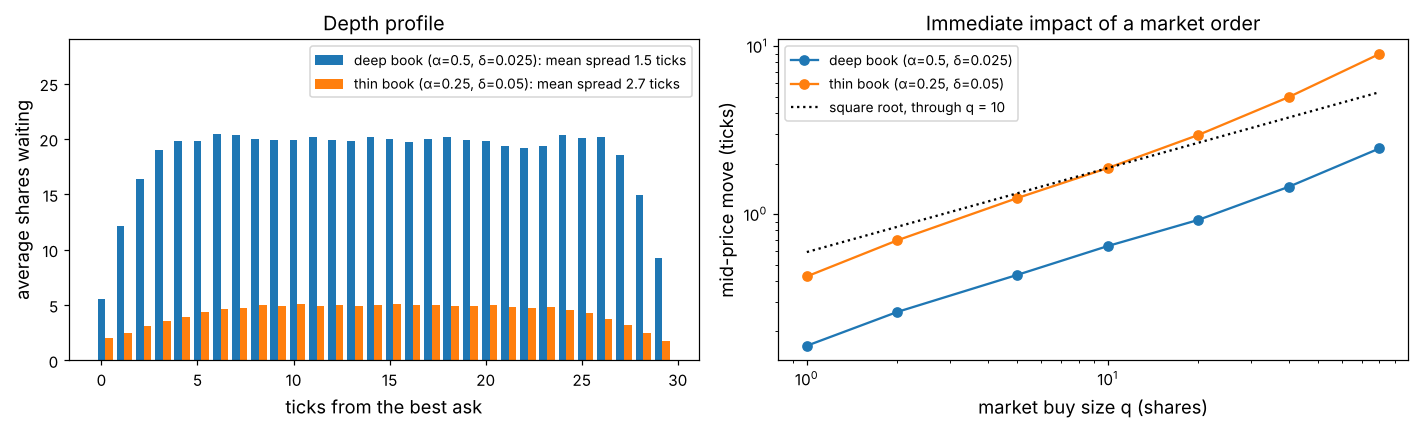

In [6]:
def zi_book(n_events, alpha, mu, delta, w=30, L=600, seed=0, every=100):
    """zero-intelligence limit order book; returns snapshots (best bid, best ask, bid depth, ask depth)"""
    rg = np.random.default_rng(seed); bid = np.zeros(L, np.int64); ask = np.zeros(L, np.int64); c = L // 2
    bid[c - w:c] = 2; ask[c + 1:c + w + 1] = 2
    U = rg.random((n_events, 3)); snaps = []
    for ev in range(n_events):
        nb, na = bid.sum(), ask.sum()
        bb = np.flatnonzero(bid)[-1]; ba = np.flatnonzero(ask)[0]
        rates = np.array([alpha * w, alpha * w, mu / 2, mu / 2, delta * nb, delta * na])
        k = np.searchsorted(np.cumsum(rates) / rates.sum(), U[ev, 0])
        if k == 0:   bid[ba - 1 - int(U[ev, 1] * w)] += 1                      # limit buy below the ask
        elif k == 1: ask[bb + 1 + int(U[ev, 1] * w)] += 1                      # limit sell above the bid
        elif k == 2 and na > 1: ask[ba] -= 1                                    # market buy
        elif k == 3 and nb > 1: bid[bb] -= 1                                    # market sell
        elif k == 4 and nb > 1: bid[min(np.searchsorted(np.cumsum(bid), U[ev, 2] * nb, side="right"), L - 1)] -= 1   # cancel a random bid
        elif k == 5 and na > 1: ask[min(np.searchsorted(np.cumsum(ask), U[ev, 2] * na, side="right"), L - 1)] -= 1
        if ev % every == 0 and ev > n_events // 10:
            snaps.append((bb, ba, bid[bb - 60:bb + 1][::-1].copy(), ask[ba:ba + 61].copy()))
        if bb < 100 or ba > L - 100:                                            # keep the book in the middle of the grid
            sh = c - (bb + ba) // 2; bid = np.roll(bid, sh); ask = np.roll(ask, sh)
    return snaps

def walk_the_book(ask_depth, q):
    """ticks the best ask moves after a market buy of q shares"""
    cum = np.cumsum(ask_depth)
    return int(np.searchsorted(cum, q, side="right")) if q < cum[-1] else len(cum)

books = {"deep book (α=0.5, δ=0.025)": dict(alpha=0.5, mu=2.0, delta=0.025), "thin book (α=0.25, δ=0.05)": dict(alpha=0.25, mu=2.0, delta=0.05)}
t0 = time.perf_counter()
sims = {name: zi_book(300_000, **p) for name, p in books.items()}
print(f"simulated 600,000 events in {time.perf_counter() - t0:.0f} s")
qs = np.array([1, 2, 5, 10, 20, 40, 80])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, S in sims.items():
    spread = np.array([s[1] - s[0] for s in S]); depth = np.mean([s[3][:30] for s in S], axis=0)
    impact = np.array([np.mean([walk_the_book(s[3], q) / 2 for s in S]) for q in qs])   # mid moves half the ask move
    ax[0].bar(np.arange(30) + (0.4 if "thin" in name else 0), depth, width=0.4, label=f"{name}: mean spread {spread.mean():.1f} ticks")
    ax[1].plot(qs, impact, "o-", label=name)
    R["spread_thin" if "thin" in name else "spread_deep"] = f"{spread.mean():.1f}"
ax[1].plot(qs, impact[3] * np.sqrt(qs / qs[3]), "k:", label="square root, through q = 10")
ax[0].set_xlabel("ticks from the best ask"); ax[0].set_ylabel("average shares waiting"); ax[0].set_ylim(top=ax[0].get_ylim()[1] * 1.35); ax[0].legend(fontsize=9); ax[0].set_title("Depth profile")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("market buy size q (shares)"); ax[1].set_ylabel("mid-price move (ticks)")
ax[1].legend(fontsize=9); ax[1].set_title("Immediate impact of a market order")
save_fig("zi_book"); plt.show()

![Figure 9-2. The simulated order book. Left: depth grows away from the best price, because orders near it are consumed first. Right: the immediate price move caused by a market order grows more slowly than its size (a straight line on this log–log plot with slope below 1), and is larger in the thinner book.](images/zi_book.png)

With no strategic behaviour at all, the simulated book has a spread of 1.5 ticks when it is deep and 2.7 when it is thin, and immediate impact is concave in order size. Real square-root impact of metaorders has a deeper cause (the book refills while you trade, and traders react to the order flow), but the qualitative lesson carries over: *the bigger the order, the cheaper each extra share, and the thinner the book, the more everything costs*.

## Project, part 2: optimal execution with Almgren–Chriss

You must sell $X$ shares by time $T$. Selling fast costs impact; selling slowly leaves you exposed to price moves. Almgren and Chriss (2000) turned this into a mean–variance problem with a closed-form solution.

:::math
Divide $[0, T]$ into $N$ intervals of length $\tau$. Let $x_k$ be the shares still held at $t_k = k\tau$ ($x_0 = X$, $x_N = 0$) and $n_k = x_{k-1} - x_k$ the shares sold in interval $k$. The price follows an arithmetic random walk $S_k = S_{k-1} + \sigma\sqrt\tau\,\xi_k$, and selling at rate $v_k = n_k/\tau$ costs a **temporary impact** $\eta v_k$ per share (permanent impact, linear in total shares, adds a constant and does not change the optimal schedule, so we drop it). The implementation shortfall then has

$$\mathbb E[\text{cost}] = \sum_{k=1}^N \frac{\eta}{\tau} n_k^2, \qquad \mathrm{Var}[\text{cost}] = \sigma^2\tau\sum_{k=1}^{N} x_k^2 .$$

Minimise $\mathbb E + \lambda\,\mathrm{Var}$ for a risk aversion $\lambda$. Setting the derivative with respect to each $x_k$ to zero gives the linear recursion $x_{k-1} - 2x_k + x_{k+1} = \tilde\kappa^2\tau^2 x_k$ with $\tilde\kappa^2 = \lambda\sigma^2/\eta$, whose solution with the boundary conditions is

$$x_k = X\,\frac{\sinh\!\big(\kappa(T - t_k)\big)}{\sinh(\kappa T)}, \qquad \frac{2}{\tau^2}\big(\cosh(\kappa\tau) - 1\big) = \frac{\lambda\sigma^2}{\eta}.$$

With $\lambda = 0$ ($\kappa \to 0$) the schedule is a straight line: TWAP. The larger $\kappa T$, the more the selling is front-loaded. Varying $\lambda$ traces the **efficient frontier** of execution: the lowest expected cost for each level of risk.
:::

A realistic example: sell 10% of AAPL's average daily volume over one trading day in 78 five-minute intervals. The temporary impact $\eta$ is set so that a TWAP execution costs what the square-root law predicts for this order.

sell 3,318,525 shares of AAPL at $329.78 ($1094m); sigma $3.71/share/sqrt(day)


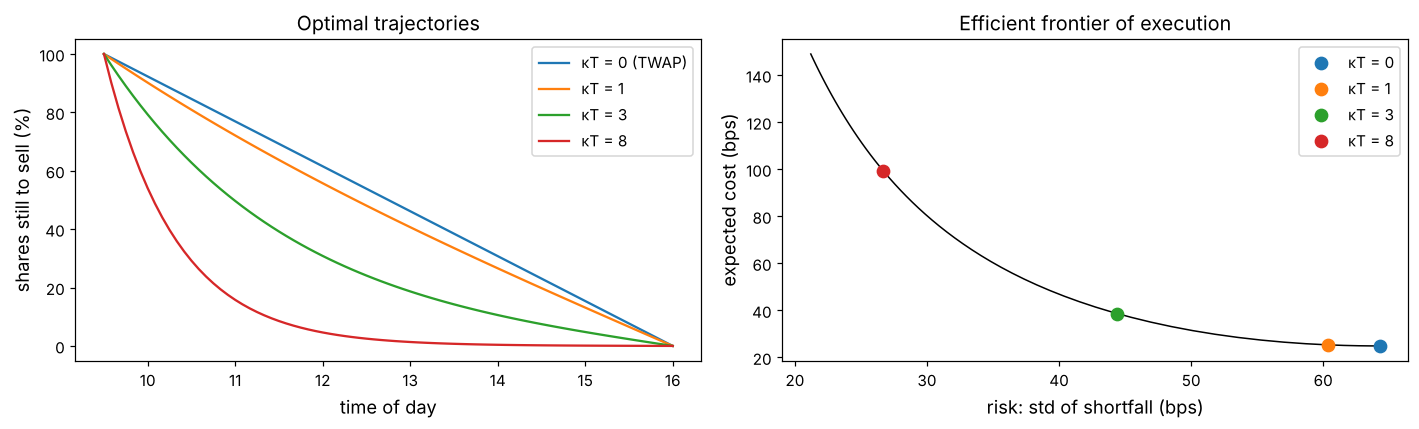

In [7]:
S0 = stats.loc["AAPL", "price"]; X = 0.10 * stats.loc["AAPL", "ADV"]
sigma = stats.loc["AAPL", "daily_vol"] * S0                  # dollars per share per sqrt(day)
T, N = 1.0, 78; tau = T / N
eta = Y * stats.loc["AAPL", "daily_vol"] * np.sqrt(0.10) * S0 * T / X     # TWAP cost per share = eta X / T = square-root cost
print(f"sell {X:,.0f} shares of AAPL at ${S0:.2f} (${X * S0 / 1e6:.0f}m); sigma ${sigma:.2f}/share/sqrt(day)")

def ac_holdings(kT):
    t = np.arange(N + 1) * tau
    return np.linspace(X, 0, N + 1) if kT == 0 else X * np.sinh(kT * (T - t) / T) / np.sinh(kT)

def ac_cost(x):
    n = -np.diff(x)
    return (eta / tau * n**2).sum(), sigma**2 * tau * (x[1:]**2).sum()     # expected cost ($), variance ($^2)

notional = X * S0
kTs = [0, 1, 3, 8]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for kT in kTs:
    x = ac_holdings(kT); E, V = ac_cost(x)
    ax[0].plot(np.arange(N + 1) * 5 / 60 + 9.5, 100 * x / X, label=f"κT = {kT}" + (" (TWAP)" if kT == 0 else ""))
frontier = np.array([ac_cost(ac_holdings(k)) for k in np.linspace(0, 12, 60)])
ax[1].plot(1e4 * np.sqrt(frontier[:, 1]) / notional, 1e4 * frontier[:, 0] / notional, "k-", lw=1)
for kT in kTs:
    E, V = ac_cost(ac_holdings(kT)); ax[1].plot(1e4 * np.sqrt(V) / notional, 1e4 * E / notional, "o", ms=8, label=f"κT = {kT}")
ax[0].set_xlabel("time of day"); ax[0].set_ylabel("shares still to sell (%)"); ax[0].legend(); ax[0].set_title("Optimal trajectories")
ax[1].set_xlabel("risk: std of shortfall (bps)"); ax[1].set_ylabel("expected cost (bps)"); ax[1].legend(); ax[1].set_title("Efficient frontier of execution")
save_fig("almgren_chriss"); plt.show()

![Figure 9-3. Almgren–Chriss. Left: the more risk-averse the trader (larger κT), the faster the position is sold at the start of the day. Right: each schedule is a point on the efficient frontier; TWAP has the lowest expected cost and the highest risk.](images/almgren_chriss.png)

The frontier is a choice, not a single answer, so simulate it: draw 20,000 price paths and compute the realised shortfall of each schedule, including selling everything in the first five minutes.

In [8]:
def simulate_shortfall(x, n_paths=20_000, seed=2):
    """realised implementation shortfall ($) of holdings path x over simulated price paths"""
    xi = np.random.default_rng(seed).standard_normal((n_paths, N))
    n = -np.diff(x)
    impact = (eta / tau * n**2).sum()
    timing = -(x[1:] * sigma * np.sqrt(tau) * xi).sum(axis=1)    # price moves on shares still held
    return impact + timing

schedules = {"all in the first 5 minutes": np.r_[X, np.zeros(N)], "TWAP (κT = 0)": ac_holdings(0),
             "Almgren–Chriss κT = 3": ac_holdings(3), "Almgren–Chriss κT = 8": ac_holdings(8)}
res = {k: simulate_shortfall(v) / notional * 1e4 for k, v in schedules.items()}
ac_tab = pd.DataFrame({k: {"mean (bps)": v.mean(), "std (bps)": v.std(), "95th percentile (bps)": np.percentile(v, 95)} for k, v in res.items()}).T
print(ac_tab.round(1))
R.update(ac_twap_mean=f"{ac_tab.iloc[1, 0]:.0f}", ac_twap_sd=f"{ac_tab.iloc[1, 1]:.0f}", ac3_mean=f"{ac_tab.iloc[2, 0]:.0f}",
         ac3_sd=f"{ac_tab.iloc[2, 1]:.0f}", ac_now=f"{ac_tab.iloc[0, 0]:.0f}", ac_twap_p95=f"{ac_tab.iloc[1, 2]:.0f}", ac3_p95=f"{ac_tab.iloc[2, 2]:.0f}")

                            mean (bps)  std (bps)  95th percentile (bps)
all in the first 5 minutes      1940.7        0.0                 1940.7
TWAP (κT = 0)                     24.6       64.0                  129.7
Almgren–Chriss κT = 3             38.6       44.3                  111.4
Almgren–Chriss κT = 8             99.6       26.6                  143.2


TWAP costs 25 basis points on average with a standard deviation of 64; the Almgren–Chriss schedule with κT = 3 costs more on average (39), because it trades faster in the morning, but its standard deviation is 44, and its bad days (95th percentile 111 against 130) are better. Dumping the whole order in five minutes would cost 1941 basis points under this model. That number is not credible (linear impact, calibrated for trading over a day, exaggerates the cost of trading 78 times faster; square-root impact grows more slowly), but every impact model agrees that it is ruinous: impact, not risk, is what makes patience necessary.

## Market making: Avellaneda–Stoikov

A market maker posts a bid and an ask around the mid and earns the spread whenever both get hit. Its danger is **inventory**: after a run of sells to it, it holds a long position just as the price may fall. Avellaneda and Stoikov (2008) derived how to shade quotes to control that risk.

:::math
The mid follows $dS = \sigma\,dW$. The market maker quotes $S - \delta^b$ and $S + \delta^a$; market orders arrive and hit the quotes with intensities $\lambda(\delta) = Ae^{-k\delta}$ (quotes further away are hit less often). With inventory $q$ and exponential utility with risk aversion $\gamma$, the solution (to first order in $q$) is:

- quote symmetrically around a **reservation price** $r = S - q\,\gamma\sigma^2(T - t)$, below the mid when long and above it when short, so that the inventory tends back to zero;
- with a total spread $\delta^a + \delta^b = \gamma\sigma^2(T - t) + \frac{2}{\gamma}\ln\!\left(1 + \frac{\gamma}{k}\right)$, which widens with risk and with how insensitive order flow is to price.

The benchmark is a **symmetric** strategy that quotes the same total spread centred on the mid, ignoring inventory.
:::

In [9]:
def market_maker(gamma=0.1, k=1.5, A=140.0, sigma=2.0, T=1.0, dt=0.005, s0=100.0, n=2000, inventory_aware=True, seed=0):
    rg = np.random.default_rng(seed); steps = int(T / dt)
    s = np.full(n, s0); q = np.zeros(n); cash = np.zeros(n); q_path = np.zeros((steps, n)); quotes = []
    for i in range(steps):
        tau_ = T - i * dt
        spread = gamma * sigma**2 * tau_ + 2 / gamma * np.log(1 + gamma / k)
        r = s - q * gamma * sigma**2 * tau_ if inventory_aware else s
        ask, bid = r + spread / 2, r - spread / 2
        hit_a = rg.random(n) < A * np.exp(-k * (ask - s)) * dt          # someone buys from us at the ask
        hit_b = rg.random(n) < A * np.exp(-k * (s - bid)) * dt          # someone sells to us at the bid
        q += hit_b.astype(float) - hit_a; cash += hit_a * ask - hit_b * bid
        quotes.append((s[0], bid[0], ask[0]))
        s = s + sigma * np.sqrt(dt) * rg.choice([-1.0, 1.0], n)
        q_path[i] = q
    return cash + q * s, q, q_path, np.array(quotes)

rows = []
for g in [0.01, 0.1, 0.5]:
    for aware in [True, False]:
        pnl, q, qp, _ = market_maker(gamma=g, inventory_aware=aware)
        rows.append((g, "inventory-aware" if aware else "symmetric", pnl.mean(), pnl.std(), pnl.mean() / pnl.std(), np.abs(q).mean(), qp.std()))
mm_tab = pd.DataFrame(rows, columns=["gamma", "strategy", "mean P&L", "std P&L", "mean / std", "mean |final inventory|", "std of inventory"]).set_index(["gamma", "strategy"])
print(mm_tab.round(2))
R["mm_aw_sd"] = f"{mm_tab.loc[(0.1, 'inventory-aware'), 'std P&L']:.1f}"; R["mm_sy_sd"] = f"{mm_tab.loc[(0.1, 'symmetric'), 'std P&L']:.1f}"
R["mm_aw_mu"] = f"{mm_tab.loc[(0.1, 'inventory-aware'), 'mean P&L']:.1f}"; R["mm_sy_mu"] = f"{mm_tab.loc[(0.1, 'symmetric'), 'mean P&L']:.1f}"

                       mean P&L  std P&L  mean / std  mean |final inventory|  \
gamma strategy                                                                 
0.01  inventory-aware     68.67     8.75        7.85                    4.12   
      symmetric           69.19    13.06        5.30                    6.88   
0.10  inventory-aware     65.09     6.49       10.03                    2.33   
      symmetric           68.48    12.81        5.35                    6.75   
0.50  inventory-aware     48.67     5.98        8.14                    1.54   
      symmetric           58.51    11.19        5.23                    5.71   

                       std of inventory  
gamma strategy                           
0.01  inventory-aware              3.38  
      symmetric                    6.08  
0.10  inventory-aware              1.40  
      symmetric                    5.85  
0.50  inventory-aware              0.72  
      symmetric                    4.51  


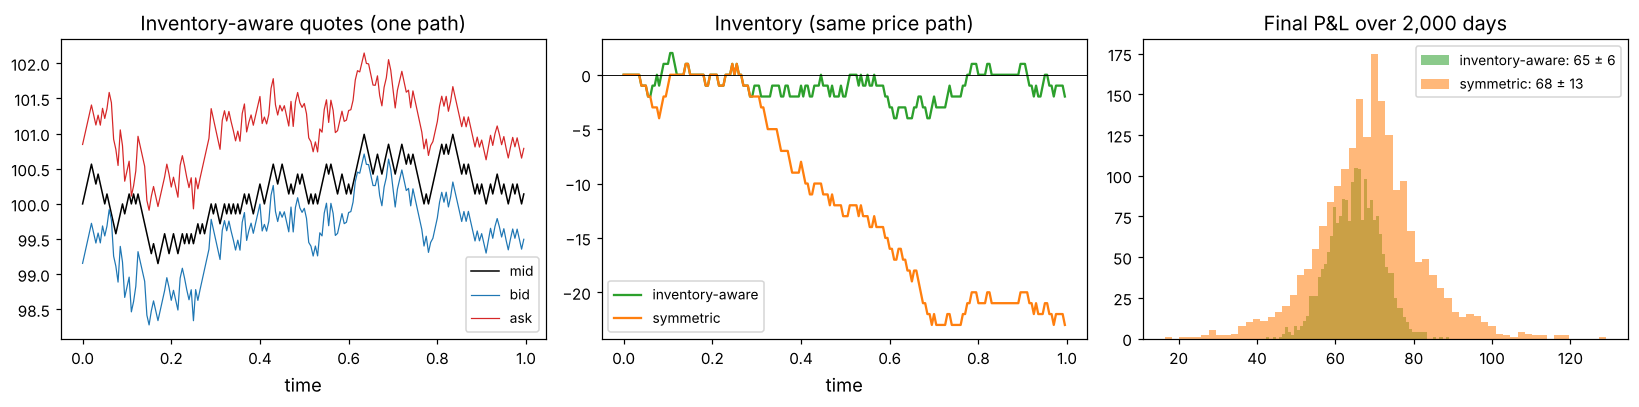

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for aware, col in [(True, "tab:green"), (False, "tab:orange")]:
    pnl, q, qp, qt = market_maker(gamma=0.1, inventory_aware=aware)
    lab = "inventory-aware" if aware else "symmetric"
    ax[1].plot(np.arange(len(qp)) * 0.005, qp[:, 0], color=col, label=lab)
    ax[2].hist(pnl, bins=60, alpha=0.55, color=col, label=f"{lab}: {pnl.mean():.0f} ± {pnl.std():.0f}")
    if aware:
        t_ = np.arange(len(qt)) * 0.005
        ax[0].plot(t_, qt[:, 0], "k", lw=1, label="mid"); ax[0].plot(t_, qt[:, 1], color="tab:blue", lw=0.8, label="bid")
        ax[0].plot(t_, qt[:, 2], color="tab:red", lw=0.8, label="ask")
ax[0].set_title("Inventory-aware quotes (one path)"); ax[0].legend(fontsize=9); ax[0].set_xlabel("time")
ax[1].set_title("Inventory (same price path)"); ax[1].axhline(0, color="k", lw=0.6); ax[1].legend(fontsize=9); ax[1].set_xlabel("time")
ax[2].set_title("Final P&L over 2,000 days"); ax[2].legend(fontsize=9)
save_fig("market_making"); plt.show()

![Figure 9-4. Avellaneda–Stoikov market making with γ = 0.1. Left: the quotes move with the mid and are shaded by inventory. Middle: the inventory-aware strategy keeps its position near zero; the symmetric one drifts. Right: both earn similar amounts on average, but the inventory-aware strategy's P&L is far more predictable.](images/market_making.png)

With $\gamma = 0.1$ the inventory-aware market maker earns 65.1 on average with a standard deviation of 6.5; the symmetric one earns 68.5 with a standard deviation of 12.8. Giving up a little expected profit to halve the risk is the whole art of market making, and it is the same trade-off as Almgren–Chriss seen from the other side of the book.

:::trap
In this model the price is a pure random walk, independent of the order flow. In real markets it is not: the traders who hit your quotes are on average better informed than you (**adverse selection**), so after you buy the price tends to fall. Exercise 2 adds a drift that follows the order flow and shows how quickly the market maker's profit disappears. Real market makers survive on speed, on knowing which flow is informed, and on exchange rebates.
:::

## Reinforcement learning: learning to execute from experience

Almgren–Chriss needed a model with a closed-form solution. **Reinforcement learning** (RL) learns a policy by trial and error from rewards, without solving equations, which matters when the state includes things no formula handles (the spread, the queue, the order flow, the time of day).

:::math
A **Markov decision process** has states $s$, actions $a$, rewards $r(s, a)$ and transitions $s \to s'$. For execution: the state is (interval $k$, shares left $x$), the action is how many shares $n$ to sell now, and the reward is minus the cost: $r = -\left(\frac{\eta}{\tau}n^2 + \lambda\sigma^2\tau(x - n)^2\right)$ plus the random price move on the shares still held. The sum of these rewards is exactly the Almgren–Chriss objective $-(\mathbb E + \lambda\mathrm{Var})$, up to zero-mean noise.

The optimal action-value function $Q^*(s, a)$, the best total reward obtainable after taking $a$ in $s$, satisfies the **Bellman equation** $Q^*(s, a) = \mathbb E\left[r + \max_{a'} Q^*(s', a')\right]$. **Q-learning** (Watkins, 1989) estimates it from experience: after each step,

$$Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \max_{a'}Q(s',a') - Q(s,a)\right],$$

choosing actions **ε-greedily** (random with probability ε, otherwise the best known). With every state visited often enough and a decreasing learning rate $\alpha$, $Q$ converges to $Q^*$.
:::

A small, normalised version of the problem: sell 20 lots in 10 intervals with $\eta = 1$ and $\lambda\sigma^2 = 0.1$. Three ways to solve it: the closed form, exact **dynamic programming** (which needs the model), and Q-learning (which only needs to try trades and see the rewards).

In [11]:
XL, NL, eta_l, lam_s2, sig_l = 20, 10, 1.0, 0.1, 0.5

def reward(x, n, eta_=eta_l):
    return -(eta_ * n**2 + lam_s2 * (x - n)**2)

kap = np.arccosh(1 + lam_s2 / (2 * eta_l))                      # tau = 1
x_closed = XL * np.sinh(kap * (NL - np.arange(NL + 1))) / np.sinh(kap * NL)

V = np.zeros((NL + 1, XL + 1)); V[NL, 1:] = -np.inf; policy_dp = np.zeros((NL, XL + 1), int)
for k in range(NL - 1, -1, -1):                                 # backward induction (Bellman with the model)
    for x in range(XL + 1):
        n = np.arange(x + 1); v = reward(x, n) + V[k + 1, x - n]
        policy_dp[k, x] = n[np.argmax(v)]; V[k, x] = v.max()

def q_learning(episodes, seed=0):
    rg = np.random.default_rng(seed); Q = np.full((NL, XL + 1, XL + 1), -np.inf)
    for k in range(NL):
        for x in range(XL + 1): Q[k, x, :x + 1] = 0.0
    for ep in range(episodes):
        eps = max(0.02, 1 - ep / (0.6 * episodes)); lr = 0.1 * (1 - ep / episodes) + 0.01; x = XL
        for k in range(NL):
            n = x if k == NL - 1 else (rg.integers(0, x + 1) if rg.random() < eps else int(np.argmax(Q[k, x, :x + 1])))
            r = reward(x, n) - (x - n) * sig_l * rg.standard_normal()
            target = r + (0.0 if k == NL - 1 else Q[k + 1, x - n, :x - n + 1].max())
            Q[k, x, n] += lr * (target - Q[k, x, n]); x -= n
    return Q

def rollout(choose):
    xs = [XL]
    for k in range(NL):
        xs.append(xs[-1] - (xs[-1] if k == NL - 1 else choose(k, xs[-1])))
    return np.array(xs)

t0 = time.perf_counter(); Q = q_learning(60_000); t_q = time.perf_counter() - t0
x_dp = rollout(lambda k, x: policy_dp[k, x]); x_q = rollout(lambda k, x: int(np.argmax(Q[k, x, :x + 1])))
objective = lambda xs: -sum(reward(xs[k], xs[k] - xs[k + 1]) for k in range(NL))
print(pd.DataFrame({"closed form": x_closed.round(2), "dynamic programming": x_dp, "Q-learning": x_q}).T.to_string())
print(f"objective (lower is better): TWAP {objective(np.linspace(XL, 0, NL + 1)):.1f}, closed form {objective(x_closed):.1f}, "
      f"DP {objective(x_dp):.1f}, Q-learning {objective(x_q):.1f}  (Q-learning trained in {t_q:.0f} s)")
R.update(q_obj=f"{objective(x_q):.1f}", dp_obj=f"{objective(x_dp):.1f}", twap_obj=f"{objective(np.linspace(XL, 0, NL + 1)):.1f}", t_q=f"{t_q:.0f}")

                       0      1     2     3     4     5     6     7     8     9    10
closed form          20.0  14.57  10.6  7.69  5.56  3.97  2.78  1.88  1.16  0.55  0.0
dynamic programming  20.0  15.00  11.0  8.00  6.00  4.00  3.00  2.00  1.00  0.00  0.0
Q-learning           20.0  14.00  10.0  7.00  5.00  4.00  3.00  2.00  2.00  2.00  0.0
objective (lower is better): TWAP 154.0, closed form 108.5, DP 109.6, Q-learning 112.7  (Q-learning trained in 5 s)


From 60,000 simulated executions, and without ever seeing the formula, Q-learning finds a front-loaded schedule almost identical to the Almgren–Chriss solution: its objective is 112.7, against 109.6 for the exact optimum and 154.0 for TWAP.

### When there is no formula: liquidity that changes

Now let liquidity switch between two regimes, **calm** ($\eta = 0.5$) and **stressed** ($\eta = 2.5$), following a Markov chain (calm stays calm with probability 0.8, stressed stays stressed with probability 0.7). The trader sees the current regime. Almgren–Chriss has no answer for this; the best it can do is use the average $\eta$. Q-learning simply adds the regime to the state.

In [12]:
etas = np.array([0.5, 2.5]); P = np.array([[0.8, 0.2], [0.3, 0.7]])
pi = np.array([P[1, 0], P[0, 1]]) / (P[1, 0] + P[0, 1])            # long-run share of time in each regime
eta_bar = pi @ etas
kap_bar = np.arccosh(1 + lam_s2 / (2 * eta_bar)); x_avg = np.round(XL * np.sinh(kap_bar * (NL - np.arange(NL + 1))) / np.sinh(kap_bar * NL)).astype(int)

# exact dynamic programming with the regime in the state (the oracle: it knows P and etas)
V2 = np.zeros((NL + 1, 2, XL + 1)); V2[NL, :, 1:] = -np.inf; pol2 = np.zeros((NL, 2, XL + 1), int)
for k in range(NL - 1, -1, -1):
    for g in range(2):
        for x in range(XL + 1):
            n = np.arange(x + 1); v = reward(x, n, etas[g]) + P[g] @ V2[k + 1][:, x - n]
            pol2[k, g, x] = n[np.argmax(v)]; V2[k, g, x] = v.max()

def q_learning_regimes(episodes, seed=1):
    rg = np.random.default_rng(seed); Q = np.full((NL, 2, XL + 1, XL + 1), -np.inf)
    for k in range(NL):
        for x in range(XL + 1): Q[k, :, x, :x + 1] = 0.0
    for ep in range(episodes):
        eps = max(0.02, 1 - ep / (0.6 * episodes)); lr = 0.1 * (1 - ep / episodes) + 0.01
        x, g = XL, rg.choice(2, p=pi)
        for k in range(NL):
            n = x if k == NL - 1 else (rg.integers(0, x + 1) if rg.random() < eps else int(np.argmax(Q[k, g, x, :x + 1])))
            r = reward(x, n, etas[g]) - (x - n) * sig_l * rg.standard_normal(); g2 = rg.choice(2, p=P[g])
            target = r + (0.0 if k == NL - 1 else Q[k + 1, g2, x - n, :x - n + 1].max())
            Q[k, g, x, n] += lr * (target - Q[k, g, x, n]); x, g = x - n, g2
    return Q

t0 = time.perf_counter(); Q2 = q_learning_regimes(150_000); t_q2 = time.perf_counter() - t0

def evaluate(choose, M=20_000, seed=5):
    rg = np.random.default_rng(seed); tot = np.zeros(M)
    for m in range(M):
        x, g = XL, rg.choice(2, p=pi)
        for k in range(NL):
            n = x if k == NL - 1 else min(x, choose(k, g, x))
            tot[m] -= reward(x, n, etas[g]); x -= n; g = rg.choice(2, p=P[g])
    return tot.mean()

pols = {"TWAP": lambda k, g, x: 2, "Almgren–Chriss with average η": lambda k, g, x: int(x_avg[k] - x_avg[k + 1]),
        "Q-learning (sees the regime)": lambda k, g, x: int(np.argmax(Q2[k, g, x, :x + 1])),
        "dynamic programming (knows the model)": lambda k, g, x: pol2[k, g, x]}
reg_tab = pd.Series({k: evaluate(f) for k, f in pols.items()}, name="expected cost + risk penalty")
print(reg_tab.round(1)); print(f"Q-learning trained in {t_q2:.0f} s; first trade when calm: {int(np.argmax(Q2[0, 0, XL]))} lots, when stressed: {int(np.argmax(Q2[0, 1, XL]))} lots")
R.update(reg_ac=f"{reg_tab.iloc[1]:.1f}", reg_q=f"{reg_tab.iloc[2]:.1f}", reg_dp=f"{reg_tab.iloc[3]:.1f}",
         reg_gain=f"{1 - reg_tab.iloc[2] / reg_tab.iloc[1]:.0%}", first_calm=int(np.argmax(Q2[0, 0, XL])), first_stress=int(np.argmax(Q2[0, 1, XL])))

TWAP                                     166.1
Almgren–Chriss with average η            131.1
Q-learning (sees the regime)             112.3
dynamic programming (knows the model)    105.8
Name: expected cost + risk penalty, dtype: float64
Q-learning trained in 26 s; first trade when calm: 8 lots, when stressed: 2 lots


The agent learns to trade hard when liquidity is good and wait when it is bad: its first trade is 8 lots in the calm regime and 2 in the stressed one. Its cost, 112.3, is 14% lower than Almgren–Chriss with the average impact (131.1) and close to the exact optimum (105.8) computed by dynamic programming *with knowledge of the model*.

:::note
Keep this result in proportion. When the model is known, dynamic programming solves it exactly and instantly; Q-learning's advantage is that it needs only experience, not the model. But experience is the problem: 150,000 executions in a simulator is cheap, 150,000 real executions is decades of trading. In practice RL for execution is trained in a **simulator** calibrated to real order-book data (such as the zero-intelligence book above, made more realistic), and its value depends entirely on how faithful that simulator is. Larger state spaces need function approximation (deep Q-networks or policy gradients) instead of a table.
:::

## Present your solution

- **Measured on real data.** Intraday volume is U-shaped and volatility highest at the open; a volume-profile schedule tracked VWAP better than TWAP out of sample for 5 of 8 tickers. Square-root-law pre-trade estimates put the cost of trading 10% of a day's volume at 10–41 basis points across the eight tickers.
- **Derived and simulated.** Almgren–Chriss trades a little expected cost for much lower risk (TWAP 25 ± 64 bps against 39 ± 44 bps for κT = 3); Avellaneda–Stoikov halves a market maker's P&L risk for a small loss of profit; a zero-intelligence book reproduces concave impact.
- **Learned.** Q-learning rediscovers the Almgren–Chriss schedule from experience alone and, when liquidity switches between regimes, beats it by 14%.
- **Limitations.** No order-book or trade-level data, so impact parameters come from the literature rather than our own fills; the market-making model has no adverse selection; the RL environments are simulators.

## Launch, monitor and maintain

- **Transaction-cost analysis (TCA) after every order.** Record the decision price, every fill and the market's volume, and compute the implementation shortfall, its split into spread, impact and timing, and the comparison with the pre-trade estimate. Over hundreds of orders, the ratio of realised to predicted cost recalibrates $Y$ and $\eta$ for your own flow.
- **Participation limits.** Cap the share of market volume you take in any interval (for example 10–15%), whatever the schedule says; it limits impact and signalling when volume dries up.
- **For market making: hard inventory and loss limits**, a kill switch that pulls all quotes when they are breached or when the data feed lags, and monitoring of markouts (the price move one, five and sixty seconds after each fill), the direct measure of adverse selection.
- **For RL policies: shadow mode first.** Run the agent alongside the production algorithm, compare the decisions it would have taken, and only then let it trade small sizes. Retrain when TCA shows the simulator has drifted from the market.

## Try it out

::playground animations/execution_lab.html 760

Three tabs: a live zero-intelligence order book you can hit with your own market orders; the Almgren–Chriss trajectory and frontier as you change risk aversion, volatility and impact; and an Avellaneda–Stoikov market maker whose risk aversion and order-flow sensitivity you control.

## Exercises

:::exercise
1. **Roll's spread estimator.** Roll (1984) showed that bid–ask bounce makes successive price changes negatively correlated, so the spread is $2\sqrt{-\mathrm{Cov}(\Delta p_t, \Delta p_{t-1})}$. Apply it day by day to the one-minute closes of SPY, AAPL and KO. On how many days is the covariance even negative, and how do the estimates compare with SPY's actual spread of one cent? Explain the failure.
2. **Adverse selection.** In the market-making simulation, make the mid move by $+\epsilon$ after each fill at the ask and by $-\epsilon$ after each fill at the bid (informed flow). Find the $\epsilon$ at which the inventory-aware market maker's average profit reaches zero.
3. **Percentage of volume.** Implement a POV schedule that trades a fixed 10% of each slot's *actual* volume until the order is done, on the 20 test days. Compare its completion time and VWAP tracking error with the profile schedule. Why is it not available in advance?
4. **Learning curves.** Train the first Q-learning agent with 2,000, 5,000, 20,000 and 60,000 episodes and plot the objective of its greedy policy against the number of episodes.
5. **Impact and resilience.** In the zero-intelligence book, measure the impact of a 20-share market buy as a function of the cancellation rate δ (0.01 to 0.1). Explain the relationship in terms of depth.
:::

<details><summary>Solutions</summary>

In [13]:
# 1
for tk in ["SPY", "AAPL", "KO"]:
    covs = np.array([np.cov(np.diff(g["close"].to_numpy())[1:], np.diff(g["close"].to_numpy())[:-1])[0, 1]
                     for _, g in b1[b1["ticker"] == tk].groupby("day")])
    neg = covs < 0
    print(f"{tk}: covariance negative on {neg.mean():.0%} of days; Roll spread on those days {200 * np.sqrt(-covs[neg]).mean():.1f} cents")

# 2
def market_maker_adverse(eps, gamma=0.1, k=1.5, A=140.0, sigma=2.0, T=1.0, dt=0.005, n=2000, seed=0):
    rg = np.random.default_rng(seed); s = np.full(n, 100.0); q = np.zeros(n); cash = np.zeros(n)
    for i in range(int(T / dt)):
        tau_ = T - i * dt; spread = gamma * sigma**2 * tau_ + 2 / gamma * np.log(1 + gamma / k); r = s - q * gamma * sigma**2 * tau_
        ask, bid = r + spread / 2, r - spread / 2
        ha = rg.random(n) < A * np.exp(-k * (ask - s)) * dt; hb = rg.random(n) < A * np.exp(-k * (s - bid)) * dt
        q += hb.astype(float) - ha; cash += ha * ask - hb * bid
        s = s + sigma * np.sqrt(dt) * rg.choice([-1.0, 1.0], n) + eps * (ha.astype(float) - hb)
    return (cash + q * s).mean()
for eps in [0.0, 0.5, 1.0, 1.5, 2.0]:
    print(f"eps = {eps}: mean P&L {market_maker_adverse(eps):.1f}")

SPY: covariance negative on 65% of days; Roll spread on those days 9.9 cents
AAPL: covariance negative on 60% of days; Roll spread on those days 8.3 cents
KO: covariance negative on 45% of days; Roll spread on those days 1.9 cents
eps = 0.0: mean P&L 65.1
eps = 0.5: mean P&L 43.9
eps = 1.0: mean P&L 22.8
eps = 1.5: mean P&L 1.6
eps = 2.0: mean P&L -19.5


The Roll estimator needs the bounce between consecutive *trades*. One-minute closes are separated by dozens or hundreds of trades, so the bounce is averaged away and the covariance is dominated by genuine price moves and noise: it is positive on a third to a half of the days, and for SPY and AAPL the other days imply spreads eight to ten times the true one-cent spread. With informed flow, every fill is followed by a move against the market maker; here the profit reaches zero at ε ≈ 1.5, about the full spread the market maker quotes (1.3 to 1.7 over the day). In real markets the informed share of the flow is unknown and changes from minute to minute, which is why markouts are watched so closely.

</details>

## What's next

The final chapter puts everything together. Chapter 10 builds a complete research pipeline from a hypothesis to a paper-trading loop, adds regime detection with hidden Markov models, and applies every safeguard from this course: point-in-time data, purged validation, realistic costs from this chapter, multiple-testing checks, and monitoring.